# Interval Bound Propagation

## Part 1 (a)

In [3]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = True
device = torch.device("cuda" if use_cuda else "cpu")
print(device)
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        # 3 hidden layers, 50 neurons per layer
        self.fc1 = nn.Linear(28*28, 50)
        self.fc2 = nn.Linear(50,50) 
        self.fc3 = nn.Linear(50,50)
        self.fc4 = nn.Linear(50,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

    # Based off of HW2 Interval Analysis code
    def forward_linear(self, lower, upper):
        lower = lower.view(-1, 28*28)
        upper = upper.view(-1, 28*28)

        for layer in [self.fc1, self.fc2, self.fc3]:
            center = (lower + upper) / 2
            diff = (upper - lower) / 2
            lower, upper = linear_bounds(layer.weight, layer.bias, center, diff)
            lower, upper = F.relu(lower), F.relu(upper)
        return lower, upper

    def output_layer(self, lower, upper, labels):
        W = self.fc4.weight
        b = self.fc4.bias
        W_y = W[labels]
        b_y = b[labels]

        j = torch.tensor(
            [[j for j in range(10) if j != y.item()] for y in labels],
            device=labels.device)

        W_diff = W_y.unsqueeze(1) - W[j]
        b_diff = b_y.unsqueeze(1) - b[j]

        center = (lower + upper) / 2
        diff = (upper - lower) / 2
        return linear_bounds(W_diff, b_diff, center, diff)

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()

cuda


Sequential(
  (0): Normalize()
  (1): Net(
    (fc1): Linear(in_features=784, out_features=50, bias=True)
    (fc2): Linear(in_features=50, out_features=50, bias=True)
    (fc3): Linear(in_features=50, out_features=50, bias=True)
    (fc4): Linear(in_features=50, out_features=10, bias=True)
  )
)

In [7]:
# Based off of HW2 Interval Analysis code
def linear_bounds(weight, bias, center, diff):
    center = center.unsqueeze(-2)
    diff = diff.unsqueeze(-2)
    weight = weight.transpose(-1, -2)

    w_mid = center.matmul(weight)
    if bias is not None:
        w_mid = w_mid + bias.unsqueeze(-2)

    w_diff = diff.matmul(weight.abs())

    lower = (w_mid - w_diff).squeeze(-2)
    upper = (w_mid + w_diff).squeeze(-2)

    return lower, upper

def ibp_loss(model, images, labels, epsilon):
    lower = torch.clamp(images - epsilon, 0, 1)
    upper = torch.clamp(images + epsilon, 0, 1)

    normalize, net = model
    lower = normalize(lower)
    upper = normalize(upper)

    lower, upper = net.forward_linear(lower, upper)
    lower, upper = net.output_layer(lower, upper, labels)

    # z_hat_K(epsilon_train)
    z_hat = torch.zeros(labels.size(0), 10, device=labels.device)
    mask = torch.ones_like(z_hat, dtype=torch.bool)
    mask.scatter_(1, labels.unsqueeze(1), False)
    z_hat = z_hat.masked_scatter(mask, -lower)

    # CE(z_hat_K(epsilon_train), y_true)
    return F.cross_entropy(z_hat, labels)

In [8]:
def train_model(model, num_epochs, robust=False):
    start_time = time.time()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        progress = epoch / max(num_epochs - 1, 1)
        kappa = 1.0 - 0.5 * progress # Decrease kappa from 1 to 0.5
        epsilon = 0.1 * progress # Increase epsilon from 0 to 0.1
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            if (robust):
                robust_loss = ibp_loss(model, images, labels, epsilon)
                loss = kappa * loss + (1 - kappa) * robust_loss
            
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')
        
    total_time = time.time() - start_time
    print(f'Training time: {total_time:.2f}s')

In [9]:
# Based off of HW3 PGD Attack code
def pgd_linf_untargeted(model, x, labels, k, eps, eps_step):
    model.eval()
    ce_loss = torch.nn.CrossEntropyLoss()
    adv_x = x.clone().detach()
    adv_x.requires_grad_(True) 
    for _ in range(k):
        adv_x.requires_grad_(True)
        model.zero_grad()
        output = model(adv_x)
        # Calculate the loss
        loss = ce_loss(output, labels)
        loss.backward()
        # Compute the adv_x
        adv_x = adv_x + eps_step * adv_x.grad.sign()
        # Find delta, clamp with eps
        delta = torch.clamp(adv_x - x, min=-eps, max=eps)
        adv_x = torch.clamp(x + delta, min=0, max=1)
        adv_x = adv_x.detach()
   
    return adv_x

In [10]:
def test_model(model, epsilon=0.1):
    model.eval()
    standard_correct = 0
    robust_correct = 0
    total = 0
    
    for data in test_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        with torch.no_grad():
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            standard_correct += (predicted == labels).sum().item()
            
        adv_images = pgd_linf_untargeted(model, images, labels, 10, epsilon, epsilon / 4)
        with torch.no_grad():
            outputs = model(adv_images)
            _, predicted = torch.max(outputs.data, 1)
            robust_correct += (predicted == labels).sum().item()
            
        total += labels.size(0)
        
    print(f'Standard accuracy: {100 * standard_correct / total:.2f}%')
    print(f'Robust accuracy: {100 * robust_correct / total:.2f}%')

In [12]:
print('Standard training:')
train_model(model, 15)
print('IBP training:')
train_model(model, 15, robust=True)

Standard training:
Epoch 1/15, Loss: 0.272
Epoch 2/15, Loss: 0.224
Epoch 3/15, Loss: 0.192
Epoch 4/15, Loss: 0.169
Epoch 5/15, Loss: 0.152
Epoch 6/15, Loss: 0.139
Epoch 7/15, Loss: 0.127
Epoch 8/15, Loss: 0.117
Epoch 9/15, Loss: 0.110
Epoch 10/15, Loss: 0.102
Epoch 11/15, Loss: 0.096
Epoch 12/15, Loss: 0.090
Epoch 13/15, Loss: 0.085
Epoch 14/15, Loss: 0.080
Epoch 15/15, Loss: 0.077
Training time: 25.32s
IBP training:
Epoch 1/15, Loss: 0.072
Epoch 2/15, Loss: 0.344
Epoch 3/15, Loss: 0.415
Epoch 4/15, Loss: 0.424
Epoch 5/15, Loss: 0.439
Epoch 6/15, Loss: 0.461
Epoch 7/15, Loss: 0.489
Epoch 8/15, Loss: 0.522
Epoch 9/15, Loss: 0.560
Epoch 10/15, Loss: 0.601
Epoch 11/15, Loss: 0.644
Epoch 12/15, Loss: 0.691
Epoch 13/15, Loss: 0.745
Epoch 14/15, Loss: 0.808
Epoch 15/15, Loss: 0.875
Training time: 121.76s


In [13]:
test_model(model)

Standard accuracy: 91.90%
Robust accuracy: 74.42%


## Part 1 (b)

In [24]:
# Based off of HW2 Interval Analysis code
def interval_analysis(model, images, labels, epsilon):
    lower = torch.clamp(images - epsilon, 0, 1)
    upper = torch.clamp(images + epsilon, 0, 1)

    normalize, net = model
    lower = normalize(lower)
    upper = normalize(upper)

    lower, upper = net.forward_linear(lower, upper) 
    lower, upper = net.output_layer(lower, upper, labels) 

    return (lower >= 0).all(dim=1)


def test_interval(model): 
    model.eval()

    eps = np.linspace(0.01, 0.1, 10)
    uncertified_examples = []
    with torch.no_grad():
        for ep in eps:
            verified = 0
            total = 0
            example = None
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                results = interval_analysis(model, images, labels, ep)
                total += labels.size(0)
                verified += results.sum().item()

                # Store one correctly classified but uncertified example
                if example is None:
                    predictions = model(images).argmax(dim=1)
                    uncertified = (~results) & (predictions == labels)
                    if uncertified.any():
                        idx = uncertified.nonzero(as_tuple=True)[0][0]
                        example = (ep, images[idx:idx+1], labels[idx:idx+1])
                        uncertified_examples.append(example)

            print(f'Epsilon: {ep:.2f}, Verified Accuracy: {100 * verified / total}%')
            
    return uncertified_examples

In [25]:
uncertified_examples = test_interval(model)

Epsilon: 0.01, Verified Accuracy: 89.99%
Epsilon: 0.02, Verified Accuracy: 88.61%
Epsilon: 0.03, Verified Accuracy: 86.81%
Epsilon: 0.04, Verified Accuracy: 84.73%
Epsilon: 0.05, Verified Accuracy: 82.75%
Epsilon: 0.06, Verified Accuracy: 80.15%
Epsilon: 0.07, Verified Accuracy: 77.23%
Epsilon: 0.08, Verified Accuracy: 73.68%
Epsilon: 0.09, Verified Accuracy: 69.52%
Epsilon: 0.10, Verified Accuracy: 64.57%


In [40]:
def find_adv_examples(model, uncertified_examples):
    model.eval()
    adv_examples = []

    for ep, image, label in uncertified_examples:
        adv_image = pgd_linf_untargeted(model, image, label, 10, ep, ep / 4)
        with torch.no_grad():
            outputs = model(adv_image)
            _, predicted = torch.max(outputs.data, 1)
        if predicted.item() != label.item():
            adv_examples.append((ep, image, label, adv_image, predicted))

    fig, axes = plt.subplots(2, len(adv_examples), figsize=(10, 5))
    for i, (ep, image, label, adv_image, predicted) in enumerate(adv_examples):
        axes[0, i].imshow(image.squeeze().cpu(), cmap='gray')
        axes[0, i].set_title(f'ε={ep:.2f}\nOriginal: {label.item()}')
        axes[0, i].axis('off')

        axes[1, i].imshow(adv_image.squeeze().cpu(), cmap='gray')
        axes[1, i].set_title(f'PGD: {predicted.item()}')
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

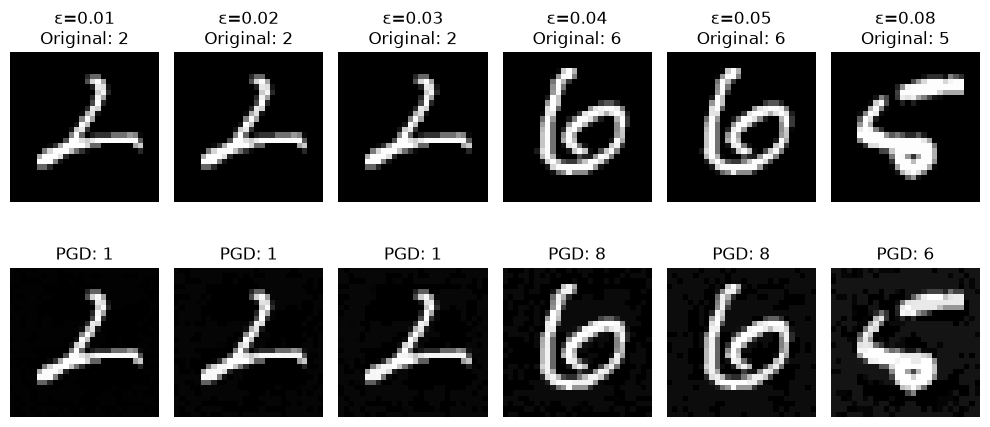

In [41]:
find_adv_examples(model, uncertified_examples)